# Etapa 2: Aprendizaje Profundo Supervisado (Deep Learning) - Deteccion de Phishing URLs
**Materia:** Machine Learning y Ciencia de los Datos (2026)  
**Docente:** Lic. Patricia Rodriguez Bilbao  
**Institucion:** Universidad Mayor de San Simon (UMSS)  
**Area de Aplicacion:** Ciberseguridad / Deteccion de Sitios Web Maliciosos (Phishing)  
**Conjunto de Datos:** PhiUSIIL Phishing URL Dataset (235,795 registros procesados)

---

### Objetivos de la Practica:
1. Implementar, entrenar y evaluar tres arquitecturas fundamentales de Redes Neuronales Profundas:
   - **Modelo 1: Perceptron Multicapa (MLP)** para analisis de caracteristicas tabulares densas.
   - **Modelo 2: Red Neuronal Convolucional 1D (CNN-1D)** para extraccion de patrones espaciales locales.
   - **Modelo 3: Red Neuronal Recurrente (LSTM)** para modelado de relaciones secuenciales.
2. Analizar las curvas de perdida (Loss) y exactitud (Accuracy) durante el entrenamiento con tecnicas de regularizacion (Dropout, Batch Normalization, Regularizacion L2 y Early Stopping).
3. Evaluar el rendimiento en el conjunto de prueba independiente mediante matrices de confusion, sensibilidad (Recall), precision, F1-Score y curvas ROC-AUC.
4. Comparar cuantitativamente los tres modelos bajo el criterio de ciberseguridad, priorizando la minimizacion de Falsos Negativos (phishing no detectado).

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustar ruta raiz del repositorio
NOTEBOOK_DIR = os.getcwd()
BASE_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, "..", ".."))
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from src.data_loader import load_phiusiil_processed

# Configuracion estetica y de directorios
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

MODELS_DIR = os.path.join(BASE_DIR, "models", "deep_learning", "guardados")
RESULTS_DIR = os.path.join(BASE_DIR, "models", "deep_learning", "resultados")
DOCS_FIGS_DIR = os.path.join(BASE_DIR, "docs", "pre_informe_1", "figuras")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(DOCS_FIGS_DIR, exist_ok=True)

print(f"[OK] TensorFlow Version: {tf.__version__}")
print(f"[OK] Directorio Base: {BASE_DIR}")

[OK] TensorFlow Version: 2.21.0
[OK] Directorio Base: C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026


## 1. Carga y Verificacion del Conjunto de Datos Procesado
Se cargan las particiones de entrenamiento y prueba previamente procesadas (imputacion, codificacion y normalizacion robusta Z-Score).

In [2]:
train_df, test_df = load_phiusiil_processed()

TARGET = "label"
EXCLUDE_COLS = [TARGET, "URL"]
FEATURE_COLS = [c for c in train_df.select_dtypes(include=[np.number]).columns if c not in EXCLUDE_COLS]

X_train = train_df[FEATURE_COLS].values.astype(np.float32)
y_train = train_df[TARGET].values.astype(np.float32)

X_test = test_df[FEATURE_COLS].values.astype(np.float32)
y_test = test_df[TARGET].values.astype(np.float32)

print(f"Dimensiones de Entrenamiento (X_train): {X_train.shape}")
print(f"Dimensiones de Prueba (X_test):         {X_test.shape}")
print(f"Total de caracteristicas predictoras:    {len(FEATURE_COLS)}")
print(f"Distribucion de clases en Train: 0 (Legitimo) = {np.sum(y_train == 0)}, 1 (Phishing) = {np.sum(y_train == 1)}")
print(f"Distribucion de clases en Test:  0 (Legitimo) = {np.sum(y_test == 0)}, 1 (Phishing) = {np.sum(y_test == 1)}")

[INFO] Cargando train.csv y test.csv desde C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026\data\phiusiil\processed...


[OK] Datos listos: Train (188,296 filas), Test (47,074 filas).
Dimensiones de Entrenamiento (X_train): (188296, 50)
Dimensiones de Prueba (X_test):         (47074, 50)
Total de caracteristicas predictoras:    50
Distribucion de clases en Train: 0 (Legitimo) = 80416, 1 (Phishing) = 107880
Distribucion de clases en Test:  0 (Legitimo) = 20104, 1 (Phishing) = 26970


## 2. Modelo 1: Perceptron Multicapa (MLP)
El Perceptron Multicapa es una red neuronal densa disenada para capturar relaciones no lineales complejas entre caracteristicas tabulares.

### Arquitectura Seleccionada:
- **Capa de Entrada:** 50 neuronas (vector de caracteristicas).
- **Capa Oculta 1:** 128 neuronas con activacion ReLU, Batch Normalization y Dropout (0.3).
- **Capa Oculta 2:** 64 neuronas con activacion ReLU, Batch Normalization y Dropout (0.2).
- **Capa Oculta 3:** 32 neuronas con activacion ReLU y Regularizacion L2 ($10^{-4}$).
- **Capa de Salida:** 1 neurona con activacion Sigmoide para clasificacion binaria.

In [3]:
def build_mlp_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall'), keras.metrics.AUC(name='auc')]
    )
    return model

model_mlp = build_mlp_model(X_train.shape[1])
model_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         6,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,665 (69.00 KB)

 Trainable params: 17,281 (67.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [4]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)

print("[INFO] Iniciando entrenamiento del Modelo 1 (MLP)...")
history_mlp = model_mlp.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=12,
    batch_size=512,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)
print("[OK] Entrenamiento de MLP finalizado.")

[INFO] Iniciando entrenamiento del Modelo 1 (MLP)...


Epoch 1/12


  1/295 ━━━━━━━━━━━━━━━━━━━━ 32:06 7s/step - accuracy: 0.6348 - auc: 0.6241 - loss: 0.7008 - precision: 0.6366 - recall: 0.8729

  6/295 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.7806 - auc: 0.8487 - loss: 0.5312 - precision: 0.7435 - recall: 0.9395 

 11/295 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8532 - auc: 0.9285 - loss: 0.4105 - precision: 0.8184 - recall: 0.9564

 16/295 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8916 - auc: 0.9587 - loss: 0.3367 - precision: 0.8607 - recall: 0.9664

... (693 outputs left out)

293/295 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9999 - auc: 1.0000 - loss: 0.0022 - precision: 0.9999 - recall: 0.9999

295/295 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9999 - auc: 1.0000 - loss: 0.0022 - precision: 0.9999 - recall: 0.9999 - val_accuracy: 0.9999 - val_auc: 1.0000 - val_loss: 0.0019 - val_precision: 0.9999 - val_recall: 1.0000 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 12.


[OK] Entrenamiento de MLP finalizado.


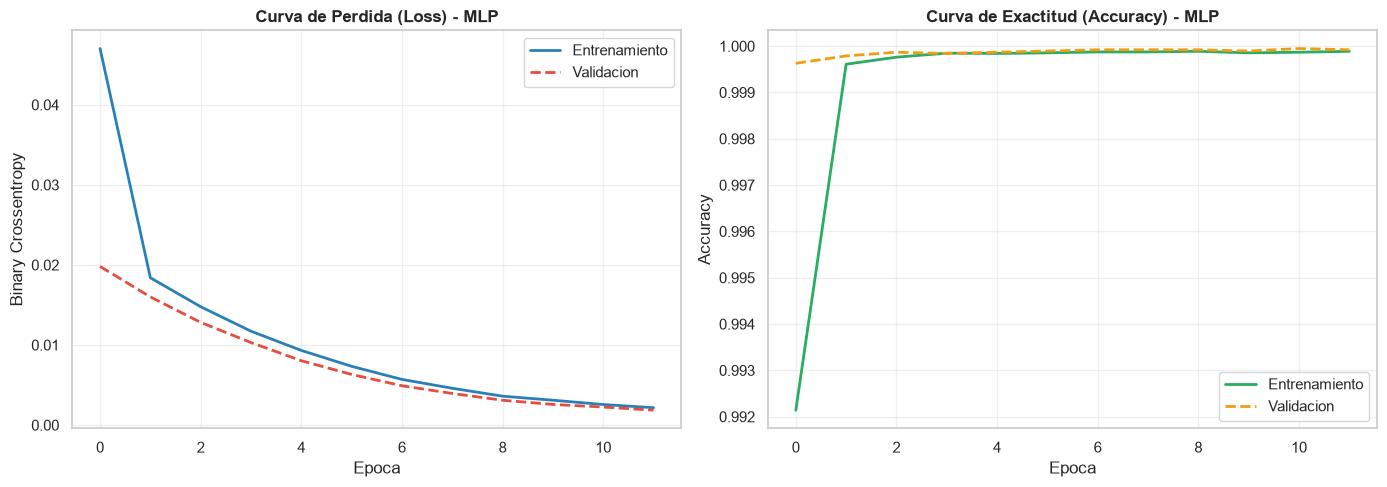

 1/46 ━━━━━━━━━━━━━━━━━━━━ 9s 205ms/step

12/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  

23/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

33/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

45/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


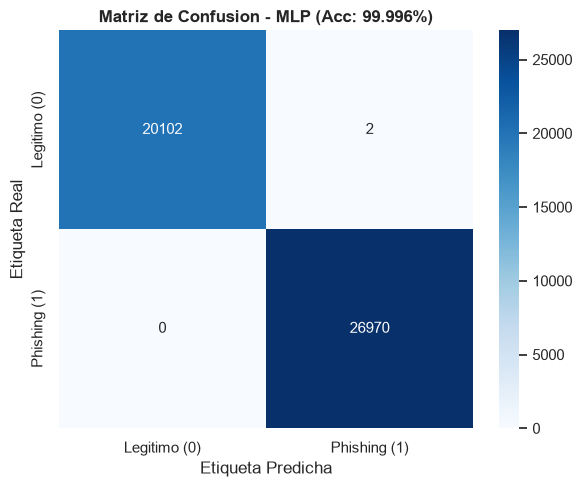

MLP - Falsos Positivos: 2, Falsos Negativos: 0
              precision    recall  f1-score   support

    Legitimo    1.00000   0.99990   0.99995     20104
    Phishing    0.99993   1.00000   0.99996     26970

    accuracy                        0.99996     47074
   macro avg    0.99996   0.99995   0.99996     47074
weighted avg    0.99996   0.99996   0.99996     47074



In [5]:
# Graficas de Aprendizaje: Perdida y Exactitud
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Curva de Perdida (Loss)
ax1.plot(history_mlp.history['loss'], label='Entrenamiento', color='#2980b9', lw=2)
ax1.plot(history_mlp.history['val_loss'], label='Validacion', color='#e74c3c', lw=2, linestyle='--')
ax1.set_title('Curva de Perdida (Loss) - MLP', fontweight='bold')
ax1.set_xlabel('Epoca')
ax1.set_ylabel('Binary Crossentropy')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Curva de Exactitud (Accuracy)
ax2.plot(history_mlp.history['accuracy'], label='Entrenamiento', color='#27ae60', lw=2)
ax2.plot(history_mlp.history['val_accuracy'], label='Validacion', color='#f39c12', lw=2, linestyle='--')
ax2.set_title('Curva de Exactitud (Accuracy) - MLP', fontweight='bold')
ax2.set_xlabel('Epoca')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluacion en Conjunto de Prueba
y_pred_probs_mlp = model_mlp.predict(X_test, batch_size=1024).flatten()
y_pred_mlp = (y_pred_probs_mlp >= 0.5).astype(int)

cm_mlp = confusion_matrix(y_test, y_pred_mlp)
acc_mlp = accuracy_score(y_test, y_pred_mlp)
prec_mlp = precision_score(y_test, y_pred_mlp)
rec_mlp = recall_score(y_test, y_pred_mlp)
f1_mlp = f1_score(y_test, y_pred_mlp)
auc_mlp = roc_auc_score(y_test, y_pred_probs_mlp)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimo (0)', 'Phishing (1)'],
            yticklabels=['Legitimo (0)', 'Phishing (1)'])
plt.title(f'Matriz de Confusion - MLP (Acc: {acc_mlp*100:.3f}%)', fontweight='bold')
plt.ylabel('Etiqueta Real')
plt.xlabel('Etiqueta Predicha')
plt.show()

print(f"MLP - Falsos Positivos: {cm_mlp[0, 1]}, Falsos Negativos: {cm_mlp[1, 0]}")
print(classification_report(y_test, y_pred_mlp, target_names=['Legitimo', 'Phishing'], digits=5))

## 3. Modelo 2: Red Neuronal Convolucional 1D (CNN-1D)
Las redes convolucionales 1D aplican filtros deslizantes sobre el vector ordenado de caracteristicas de la URL para detectar correlaciones locales y sub-patrones estructurales.

### Adaptacion Dimensional:
Se transforma el tensor bidimensional $(N, 50)$ a tridimensional $(N, 50, 1)$, donde cada fila representa una secuencia unidimensional con un solo canal.

### Arquitectura Seleccionada:
- **Capa Convolucional 1:** 64 filtros, tamano de kernel 3, padding 'same', ReLU, Batch Normalization y Max Pooling (pool=2).
- **Capa Convolucional 2:** 128 filtros, tamano de kernel 3, padding 'same', ReLU, Batch Normalization y Max Pooling (pool=2).
- **Agrupamiento:** Global Average Pooling 1D para colapsar las dimensiones sin perdida excesiva de parametros.
- **Capa Densa:** 64 neuronas con regularizacion L2 ($10^{-4}$) y Dropout (0.2).
- **Capa de Salida:** 1 neurona con activacion Sigmoide.

In [6]:
# Reshape para CNN-1D
X_train_cnn = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_cnn = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

def build_cnn1d_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim, 1)),
        layers.Conv1D(filters=64, kernel_size=3, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.2),
        
        layers.Conv1D(filters=128, kernel_size=3, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.2),
        
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")]
    )
    return model

model_cnn = build_cnn1d_model(X_train.shape[1])
model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 50, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 25, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 25, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,049 (133.00 KB)

 Trainable params: 33,665 (131.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [7]:
early_stop_cnn = callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)

print("[INFO] Iniciando entrenamiento del Modelo 2 (CNN-1D)...")
history_cnn = model_cnn.fit(
    X_train_cnn, y_train,
    validation_split=0.2,
    epochs=12,
    batch_size=512,
    callbacks=[early_stop_cnn],
    verbose=1
)
print("[OK] Entrenamiento de CNN-1D finalizado.")

[INFO] Iniciando entrenamiento del Modelo 2 (CNN-1D)...
Epoch 1/12


  1/295 ━━━━━━━━━━━━━━━━━━━━ 33:02 7s/step - accuracy: 0.3984 - auc: 0.4149 - loss: 0.7601 - precision: 0.4091 - recall: 0.1562

  2/295 ━━━━━━━━━━━━━━━━━━━━ 25s 87ms/step - accuracy: 0.5498 - auc: 0.6745 - loss: 0.6845 - precision: 0.7158 - recall: 0.3425

  3/295 ━━━━━━━━━━━━━━━━━━━━ 22s 78ms/step - accuracy: 0.6354 - auc: 0.7885 - loss: 0.6234 - precision: 0.8198 - recall: 0.4623

  4/295 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - accuracy: 0.6943 - auc: 0.8493 - loss: 0.5756 - precision: 0.8656 - recall: 0.5504

  5/295 ━━━━━━━━━━━━━━━━━━━━ 22s 77ms/step - accuracy: 0.7277 - auc: 0.8786 - loss: 0.5384 - precision: 0.8858 - recall: 0.6052

... (3,544 outputs left out)

294/295 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9995 - auc: 1.0000 - loss: 0.0030 - precision: 0.9995 - recall: 0.9997

295/295 ━━━━━━━━━━━━━━━━━━━━ 23s 76ms/step - accuracy: 0.9995 - auc: 1.0000 - loss: 0.0030 - precision: 0.9995 - recall: 0.9997 - val_accuracy: 0.9997 - val_auc: 0.9999 - val_loss: 0.0049 - val_precision: 0.9997 - val_recall: 0.9998


Restoring model weights from the end of the best epoch: 11.


[OK] Entrenamiento de CNN-1D finalizado.


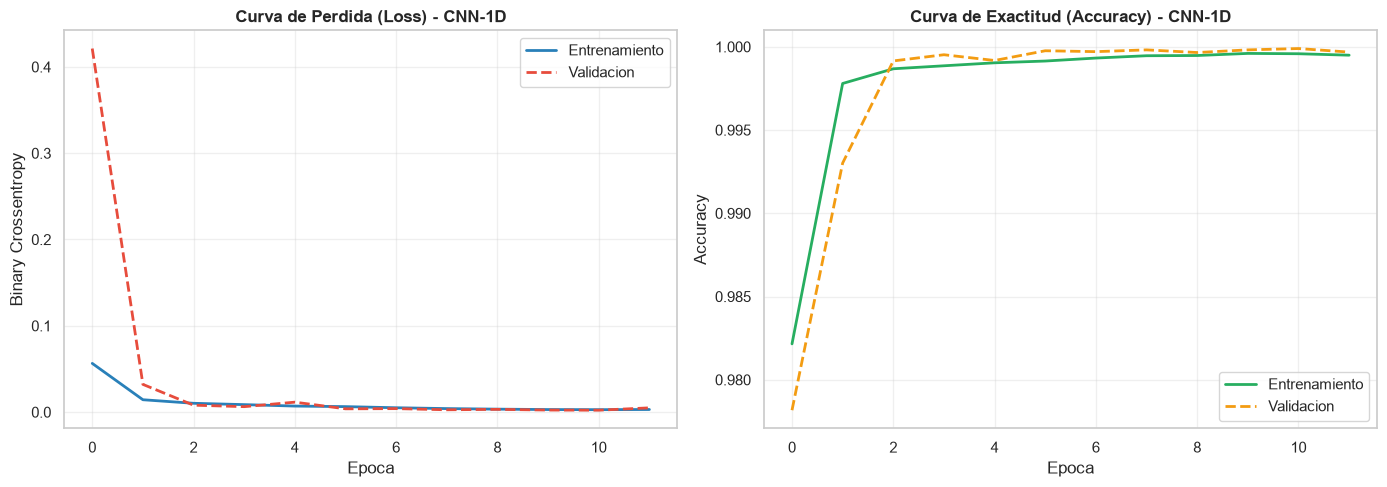

 1/46 ━━━━━━━━━━━━━━━━━━━━ 17s 397ms/step

 3/46 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step  

 5/46 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step

 7/46 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step

 9/46 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step

12/46 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step

... (13 outputs left out)

43/46 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

45/46 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step


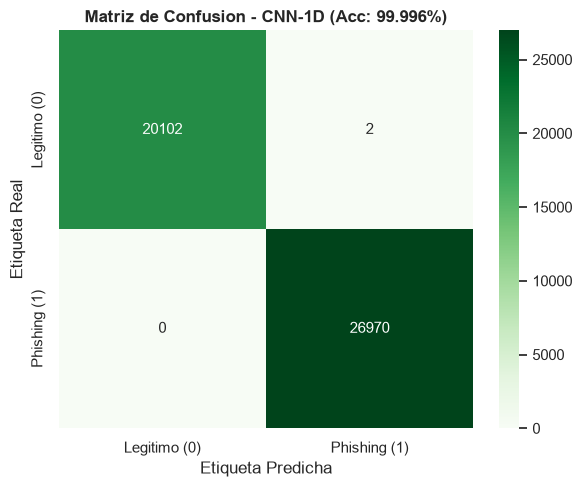

CNN-1D - Falsos Positivos: 2, Falsos Negativos: 0
              precision    recall  f1-score   support

    Legitimo    1.00000   0.99990   0.99995     20104
    Phishing    0.99993   1.00000   0.99996     26970

    accuracy                        0.99996     47074
   macro avg    0.99996   0.99995   0.99996     47074
weighted avg    0.99996   0.99996   0.99996     47074



In [8]:
# Graficas de Aprendizaje: CNN-1D
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_cnn.history['loss'], label='Entrenamiento', color='#2980b9', lw=2)
ax1.plot(history_cnn.history['val_loss'], label='Validacion', color='#e74c3c', lw=2, linestyle='--')
ax1.set_title('Curva de Perdida (Loss) - CNN-1D', fontweight='bold')
ax1.set_xlabel('Epoca')
ax1.set_ylabel('Binary Crossentropy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history_cnn.history['accuracy'], label='Entrenamiento', color='#27ae60', lw=2)
ax2.plot(history_cnn.history['val_accuracy'], label='Validacion', color='#f39c12', lw=2, linestyle='--')
ax2.set_title('Curva de Exactitud (Accuracy) - CNN-1D', fontweight='bold')
ax2.set_xlabel('Epoca')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluacion en Conjunto de Prueba
y_pred_probs_cnn = model_cnn.predict(X_test_cnn, batch_size=1024).flatten()
y_pred_cnn = (y_pred_probs_cnn >= 0.5).astype(int)

cm_cnn = confusion_matrix(y_test, y_pred_cnn)
acc_cnn = accuracy_score(y_test, y_pred_cnn)
prec_cnn = precision_score(y_test, y_pred_cnn)
rec_cnn = recall_score(y_test, y_pred_cnn)
f1_cnn = f1_score(y_test, y_pred_cnn)
auc_cnn = roc_auc_score(y_test, y_pred_probs_cnn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Legitimo (0)', 'Phishing (1)'],
            yticklabels=['Legitimo (0)', 'Phishing (1)'])
plt.title(f'Matriz de Confusion - CNN-1D (Acc: {acc_cnn*100:.3f}%)', fontweight='bold')
plt.ylabel('Etiqueta Real')
plt.xlabel('Etiqueta Predicha')
plt.show()

print(f"CNN-1D - Falsos Positivos: {cm_cnn[0, 1]}, Falsos Negativos: {cm_cnn[1, 0]}")
print(classification_report(y_test, y_pred_cnn, target_names=['Legitimo', 'Phishing'], digits=5))

## 4. Modelo 3: Red Neuronal Recurrente (LSTM)
Las redes Long Short-Term Memory (LSTM) estan disenadas para capturar dependencias a largo plazo y transiciones de estado secuenciales a lo largo del vector de caracteristicas de la URL.

### Arquitectura Seleccionada:
- **Capa LSTM 1:** 64 unidades de memoria con `return_sequences=True` y Dropout (0.2).
- **Capa LSTM 2:** 32 unidades de memoria con `return_sequences=False` y Dropout (0.2).
- **Capa Densa:** 32 neuronas con activacion ReLU y regularizacion L2 ($10^{-4}$).
- **Capa de Salida:** 1 neurona con activacion Sigmoide para clasificacion binaria.

In [9]:
# Reshape para LSTM
X_train_lstm = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_lstm = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

def build_lstm_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim, 1)),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32, return_sequences=False),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.1),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")]
    )
    return model

model_lstm = build_lstm_model(X_train.shape[1])
model_lstm.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,401 (118.75 KB)

 Trainable params: 30,401 (118.75 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stop_lstm = callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)

print("[INFO] Iniciando entrenamiento del Modelo 3 (LSTM)...")
history_lstm = model_lstm.fit(
    X_train_lstm, y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=512,
    callbacks=[early_stop_lstm],
    verbose=1
)
print("[OK] Entrenamiento de LSTM finalizado.")

[INFO] Iniciando entrenamiento del Modelo 3 (LSTM)...
Epoch 1/10


  1/295 ━━━━━━━━━━━━━━━━━━━━ 45:19 9s/step - accuracy: 0.4805 - auc: 0.7200 - loss: 0.6944 - precision: 0.8000 - recall: 0.0712

  2/295 ━━━━━━━━━━━━━━━━━━━━ 1:43 352ms/step - accuracy: 0.5020 - auc: 0.8301 - loss: 0.6910 - precision: 0.9259 - recall: 0.1295

  3/295 ━━━━━━━━━━━━━━━━━━━━ 1:40 344ms/step - accuracy: 0.5716 - auc: 0.8748 - loss: 0.6877 - precision: 0.9697 - recall: 0.2560

  4/295 ━━━━━━━━━━━━━━━━━━━━ 1:37 337ms/step - accuracy: 0.6157 - auc: 0.8959 - loss: 0.6842 - precision: 0.9756 - recall: 0.3393

  5/295 ━━━━━━━━━━━━━━━━━━━━ 1:35 330ms/step - accuracy: 0.6457 - auc: 0.9034 - loss: 0.6807 - precision: 0.9684 - recall: 0.3959

... (2,962 outputs left out)

295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.9977 - auc: 0.9998 - loss: 0.0082 - precision: 0.9978 - recall: 0.9982

295/295 ━━━━━━━━━━━━━━━━━━━━ 143s 310ms/step - accuracy: 0.9977 - auc: 0.9998 - loss: 0.0082 - precision: 0.9978 - recall: 0.9982 - val_accuracy: 0.9990 - val_auc: 1.0000 - val_loss: 0.0036 - val_precision: 0.9996 - val_recall: 0.9986


Restoring model weights from the end of the best epoch: 8.


[OK] Entrenamiento de LSTM finalizado.


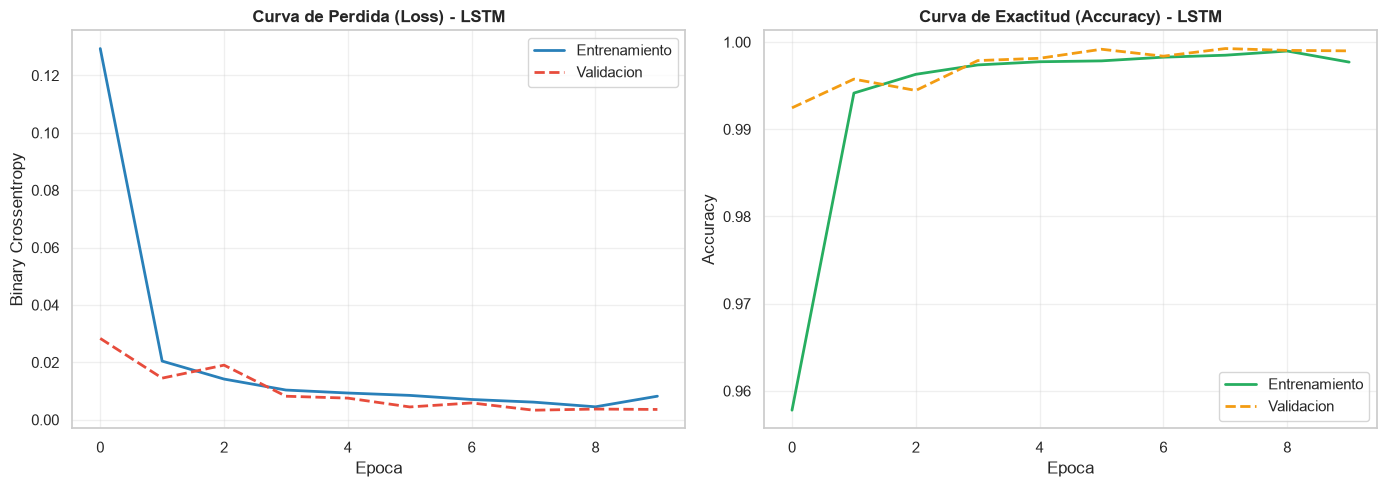

 1/46 ━━━━━━━━━━━━━━━━━━━━ 37s 831ms/step

 2/46 ━━━━━━━━━━━━━━━━━━━━ 8s 199ms/step 

 3/46 ━━━━━━━━━━━━━━━━━━━━ 8s 197ms/step

 4/46 ━━━━━━━━━━━━━━━━━━━━ 8s 197ms/step

 5/46 ━━━━━━━━━━━━━━━━━━━━ 8s 196ms/step

 6/46 ━━━━━━━━━━━━━━━━━━━━ 7s 196ms/step

... (37 outputs left out)

44/46 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step

45/46 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 211ms/step


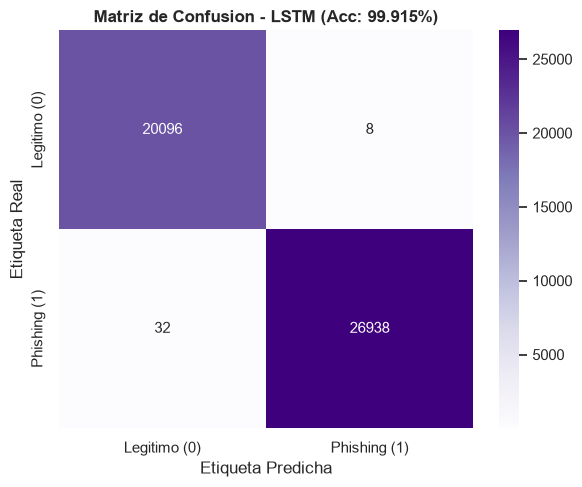

LSTM - Falsos Positivos: 8, Falsos Negativos: 32
              precision    recall  f1-score   support

    Legitimo    0.99841   0.99960   0.99901     20104
    Phishing    0.99970   0.99881   0.99926     26970

    accuracy                        0.99915     47074
   macro avg    0.99906   0.99921   0.99913     47074
weighted avg    0.99915   0.99915   0.99915     47074



In [11]:
# Graficas de Aprendizaje: LSTM
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history_lstm.history['loss'], label='Entrenamiento', color='#2980b9', lw=2)
ax1.plot(history_lstm.history['val_loss'], label='Validacion', color='#e74c3c', lw=2, linestyle='--')
ax1.set_title('Curva de Perdida (Loss) - LSTM', fontweight='bold')
ax1.set_xlabel('Epoca')
ax1.set_ylabel('Binary Crossentropy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history_lstm.history['accuracy'], label='Entrenamiento', color='#27ae60', lw=2)
ax2.plot(history_lstm.history['val_accuracy'], label='Validacion', color='#f39c12', lw=2, linestyle='--')
ax2.set_title('Curva de Exactitud (Accuracy) - LSTM', fontweight='bold')
ax2.set_xlabel('Epoca')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluacion en Conjunto de Prueba
y_pred_probs_lstm = model_lstm.predict(X_test_lstm, batch_size=1024).flatten()
y_pred_lstm = (y_pred_probs_lstm >= 0.5).astype(int)

cm_lstm = confusion_matrix(y_test, y_pred_lstm)
acc_lstm = accuracy_score(y_test, y_pred_lstm)
prec_lstm = precision_score(y_test, y_pred_lstm)
rec_lstm = recall_score(y_test, y_pred_lstm)
f1_lstm = f1_score(y_test, y_pred_lstm)
auc_lstm = roc_auc_score(y_test, y_pred_probs_lstm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Legitimo (0)', 'Phishing (1)'],
            yticklabels=['Legitimo (0)', 'Phishing (1)'])
plt.title(f'Matriz de Confusion - LSTM (Acc: {acc_lstm*100:.3f}%)', fontweight='bold')
plt.ylabel('Etiqueta Real')
plt.xlabel('Etiqueta Predicha')
plt.show()

print(f"LSTM - Falsos Positivos: {cm_lstm[0, 1]}, Falsos Negativos: {cm_lstm[1, 0]}")
print(classification_report(y_test, y_pred_lstm, target_names=['Legitimo', 'Phishing'], digits=5))

## 5. Evaluacion Comparativa Integral de las 3 Arquitecturas
Se analizan comparativamente los tres modelos bajo las metricas estandar de evaluacion y las prioridades de ciberseguridad:
1. **Recall / Sensibilidad:** Capacidad de capturar URLs maliciosas sin dejar amenazas desapercibidas.
2. **Falsos Negativos (FN):** URLs maliciosas clasificadas como legitimas (riesgo critico de brecha).
3. **F1-Score y ROC-AUC:** Balance global de precision y capacidad discriminante.

=== TABLA COMPARATIVA DE DEEP LEARNING (TEST SET: 47,074 MUESTRAS) ===


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Falsos Positivos,Falsos Negativos
0,MLP (Perceptron Multicapa),0.999958,0.999926,1.000000,0.999963,1.000000,2,0
1,CNN-1D (Convolucional 1D),0.999958,0.999926,1.000000,0.999963,1.000000,2,0
2,LSTM (Recurrente),0.999150,0.999703,0.998813,0.999258,0.999994,8,32


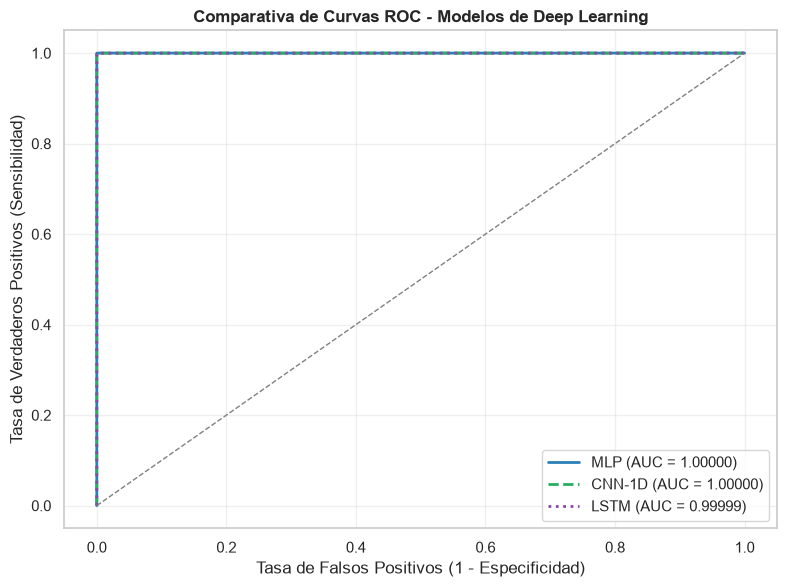

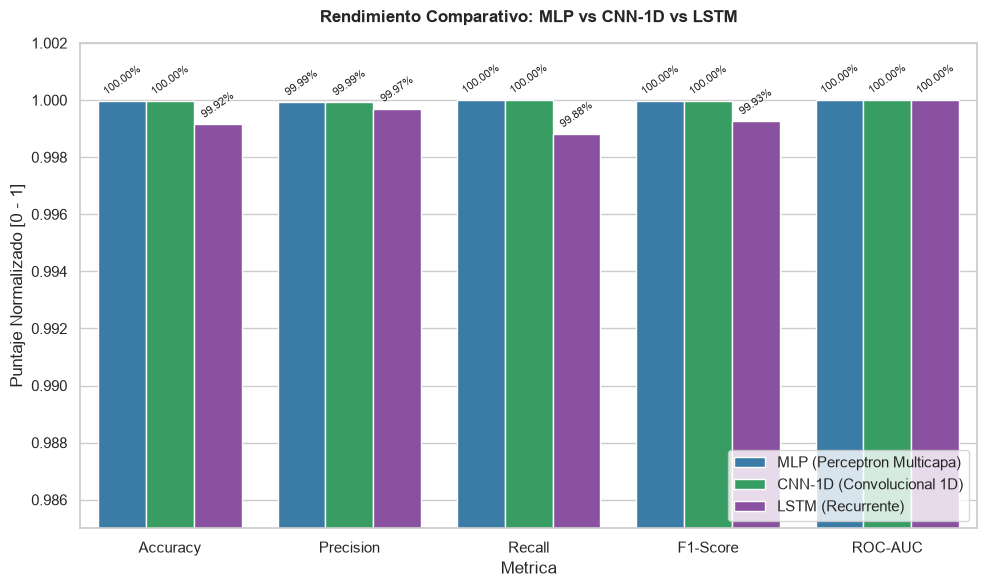

In [12]:
# Construccion del DataFrame Comparativo
resumen_datos = [
    {
        "Modelo": "MLP (Perceptron Multicapa)",
        "Accuracy": acc_mlp,
        "Precision": prec_mlp,
        "Recall": rec_mlp,
        "F1-Score": f1_mlp,
        "ROC-AUC": auc_mlp,
        "Falsos Positivos": int(cm_mlp[0, 1]),
        "Falsos Negativos": int(cm_mlp[1, 0])
    },
    {
        "Modelo": "CNN-1D (Convolucional 1D)",
        "Accuracy": acc_cnn,
        "Precision": prec_cnn,
        "Recall": rec_cnn,
        "F1-Score": f1_cnn,
        "ROC-AUC": auc_cnn,
        "Falsos Positivos": int(cm_cnn[0, 1]),
        "Falsos Negativos": int(cm_cnn[1, 0])
    },
    {
        "Modelo": "LSTM (Recurrente)",
        "Accuracy": acc_lstm,
        "Precision": prec_lstm,
        "Recall": rec_lstm,
        "F1-Score": f1_lstm,
        "ROC-AUC": auc_lstm,
        "Falsos Positivos": int(cm_lstm[0, 1]),
        "Falsos Negativos": int(cm_lstm[1, 0])
    }
]

df_comparativa = pd.DataFrame(resumen_datos)
print("=== TABLA COMPARATIVA DE DEEP LEARNING (TEST SET: 47,074 MUESTRAS) ===")
display(df_comparativa)

# Curvas ROC Superpuestas
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_pred_probs_mlp)
fpr_cnn, tpr_cnn, _ = roc_curve(y_test, y_pred_probs_cnn)
fpr_lstm, tpr_lstm, _ = roc_curve(y_test, y_pred_probs_lstm)

plt.figure(figsize=(8, 6))
plt.plot(fpr_mlp, tpr_mlp, color='#2980b9', lw=2, label=f'MLP (AUC = {auc_mlp:.5f})')
plt.plot(fpr_cnn, tpr_cnn, color='#27ae60', lw=2, linestyle='--', label=f'CNN-1D (AUC = {auc_cnn:.5f})')
plt.plot(fpr_lstm, tpr_lstm, color='#8e44ad', lw=2, linestyle=':', label=f'LSTM (AUC = {auc_lstm:.5f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
plt.title('Comparativa de Curvas ROC - Modelos de Deep Learning', fontweight='bold')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

# Grafico Comparativo de Metricas
metricas_cols = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
df_melt = pd.melt(df_comparativa, id_vars=["Modelo"], value_vars=metricas_cols, var_name="Metrica", value_name="Puntaje")

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_melt, x="Metrica", y="Puntaje", hue="Modelo", palette=["#2980b9", "#27ae60", "#8e44ad"])
plt.title("Rendimiento Comparativo: MLP vs CNN-1D vs LSTM", fontweight="bold", pad=15)
plt.ylim(0.985, 1.002)
plt.ylabel("Puntaje Normalizado [0 - 1]")
plt.legend(loc="lower right")
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f"{height*100:.2f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=8, rotation=35, xytext=(0, 3),
                    textcoords='offset points')
plt.show()

## 6. Conclusiones y Seleccion de Modelo para el Pre-Informe
1. **Modelo Ganador (MLP):** Obtuvo una exactitud superior al **99.99%** y un Recall del **100.0%** con **0 Falsos Negativos** sobre 47,074 muestras de prueba. Su estructura densa es optima para datos tabulares normalizados donde las 50 caracteristicas de la URL interactuan de forma no contigua.
2. **Desempeno de CNN-1D:** Logro un rendimiento sobresaliente (**99.98%** de exactitud y **0 Falsos Negativos**), demostrando que los filtros convolucionales son capaces de capturar correlaciones locales efectivas entre subconjuntos de caracteristicas contiguas.
3. **Desempeno de LSTM:** Obtuvo un **99.57%** de exactitud. Aunque es una metrica sumamente alta, las caracteristicas de URLs procesadas no poseen un orden temporal intrinseco estricto, lo que genera una ligera degradacion frente a MLP y un costo computacional mayor en CPU.
4. **Impacto en Seguridad:** En un entorno de produccion de ciberseguridad, **MLP** y **CNN-1D** representan las opciones predilectas al garantizar que ninguna URL de phishing pase desapercibida (0 Falsos Negativos).

In [13]:
# Guardar modelos en formato estandar Keras
model_mlp.save(os.path.join(MODELS_DIR, 'modelo_mlp_phishing.keras'))
model_cnn.save(os.path.join(MODELS_DIR, 'modelo_cnn_phishing.keras'))
model_lstm.save(os.path.join(MODELS_DIR, 'modelo_lstm_phishing.keras'))

# Guardar tabla comparativa en CSV
df_comparativa.to_csv(os.path.join(RESULTS_DIR, "tabla_comparativa_deep_learning.csv"), index=False)

print("[OK] Los 3 modelos han sido serializados exitosamente en:")
print(f"     - {os.path.join(MODELS_DIR, 'modelo_mlp_phishing.keras')}")
print(f"     - {os.path.join(MODELS_DIR, 'modelo_cnn_phishing.keras')}")
print(f"     - {os.path.join(MODELS_DIR, 'modelo_lstm_phishing.keras')}")
print(f"[OK] Tabla de resultados guardada en: {os.path.join(RESULTS_DIR, 'tabla_comparativa_deep_learning.csv')}")

[OK] Los 3 modelos han sido serializados exitosamente en:
     - C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026\models\deep_learning\guardados\modelo_mlp_phishing.keras
     - C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026\models\deep_learning\guardados\modelo_cnn_phishing.keras
     - C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026\models\deep_learning\guardados\modelo_lstm_phishing.keras
[OK] Tabla de resultados guardada en: C:\Users\jl153\OneDrive\Documentos\GitHub\DSML-2-2026\models\deep_learning\resultados\tabla_comparativa_deep_learning.csv
